In [ ]:
!pip install -q ultralytics

from google.colab import drive
drive.mount('/content/drive')

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 46.9/46.9 kB 1.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 25.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 58.1/58.1 kB 3.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 96.5/96.5 kB 6.8 MB/s eta 0:00:00
Mounted at /content/drive


In [ ]:
from pathlib import Path
import random
import pandas as pd
from IPython.display import Image as IPImage, display
from ultralytics import YOLO

GRID_DIR = Path("/content/drive/MyDrive/Objectdetection/data/grid_dataset")
RUNS_DIR = Path("/content/drive/MyDrive/Objectdetection/runs")
RUN_NAME = "yolov8s_grid"
TEST_DIR = RUNS_DIR / f"{RUN_NAME}_test"

best_model = YOLO(str(RUNS_DIR / RUN_NAME / "weights" / "best.pt"))

metrics = best_model.val(
    data=str(GRID_DIR / "data.yaml"),
    split="test",
    imgsz=1024,
    batch=16,
    plots=True,
    project=str(RUNS_DIR),
    name=TEST_DIR.name,
    exist_ok=True,
)

print(f"mAP50:     {metrics.box.map50:.4f}")
print(f"mAP50-95:  {metrics.box.map:.4f}")
print(f"Precision: {metrics.box.mp:.4f}")
print(f"Recall:    {metrics.box.mr:.4f}")

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.
Ultralytics 8.4.175 🚀 Python-3.13.16 torch-2.11.0+cpu CPU (Intel Xeon CPU @ 2.20GHz)
Model summary (fused): 72 layers, 11,153,835 parameters, 0 gradients, 28.6 GFLOPs
WARNING ⚠️ val: Slow image access detected (ping: 0.8±0.1 ms, read: 1.1±0.7 MB/s, size: 246.3 KB). Use local storage instead of remote/mounted storage for better performance. See https://docs.ultralytics.com/guides/model-training-tips
val: Scanning /content/drive/.shortcut-targets-by-id/1NXn7oX20Aw8ERXLlPt4_IGABaGaJsOWN/Objectdetection/data/grid_dataset/labels/test.cache... 561 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 561/561 75.9Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50

In [ ]:
per_class = pd.DataFrame({
    "class": [metrics.names[i] for i in metrics.box.ap_class_index],
    "precision": metrics.box.p,
    "recall": metrics.box.r,
    "mAP50": metrics.box.ap50,
    "mAP50-95": metrics.box.ap,
}).sort_values("mAP50-95").reset_index(drop=True)

per_class.to_csv(TEST_DIR / "per_class_metrics.csv", index=False)

display(per_class.round(4))
print(f"Saved: {TEST_DIR / 'per_class_metrics.csv'}")

,class,precision,recall,mAP50,mAP50-95
0,OBJ068,0.4056,0.3549,0.3519,0.2919
1,OBJ060,0.6328,0.5000,0.4402,0.4003
2,OBJ050,0.6095,0.4099,0.4580,0.4210
3,OBJ065,0.6724,0.6429,0.4805,0.4382
4,OBJ059,0.8230,0.4571,0.5293,0.4841
...,...,...,...,...,...
68,OBJ018,0.9471,1.0000,0.9950,0.9917
69,OBJ001,0.9933,1.0000,0.9950,0.9918
70,OBJ033,0.9971,1.0000,0.9950,0.9939
71,OBJ002,0.9855,1.0000,0.9950,0.9939


Saved: /content/drive/MyDrive/Objectdetection/runs/yolov8s_grid_test/per_class_metrics.csv


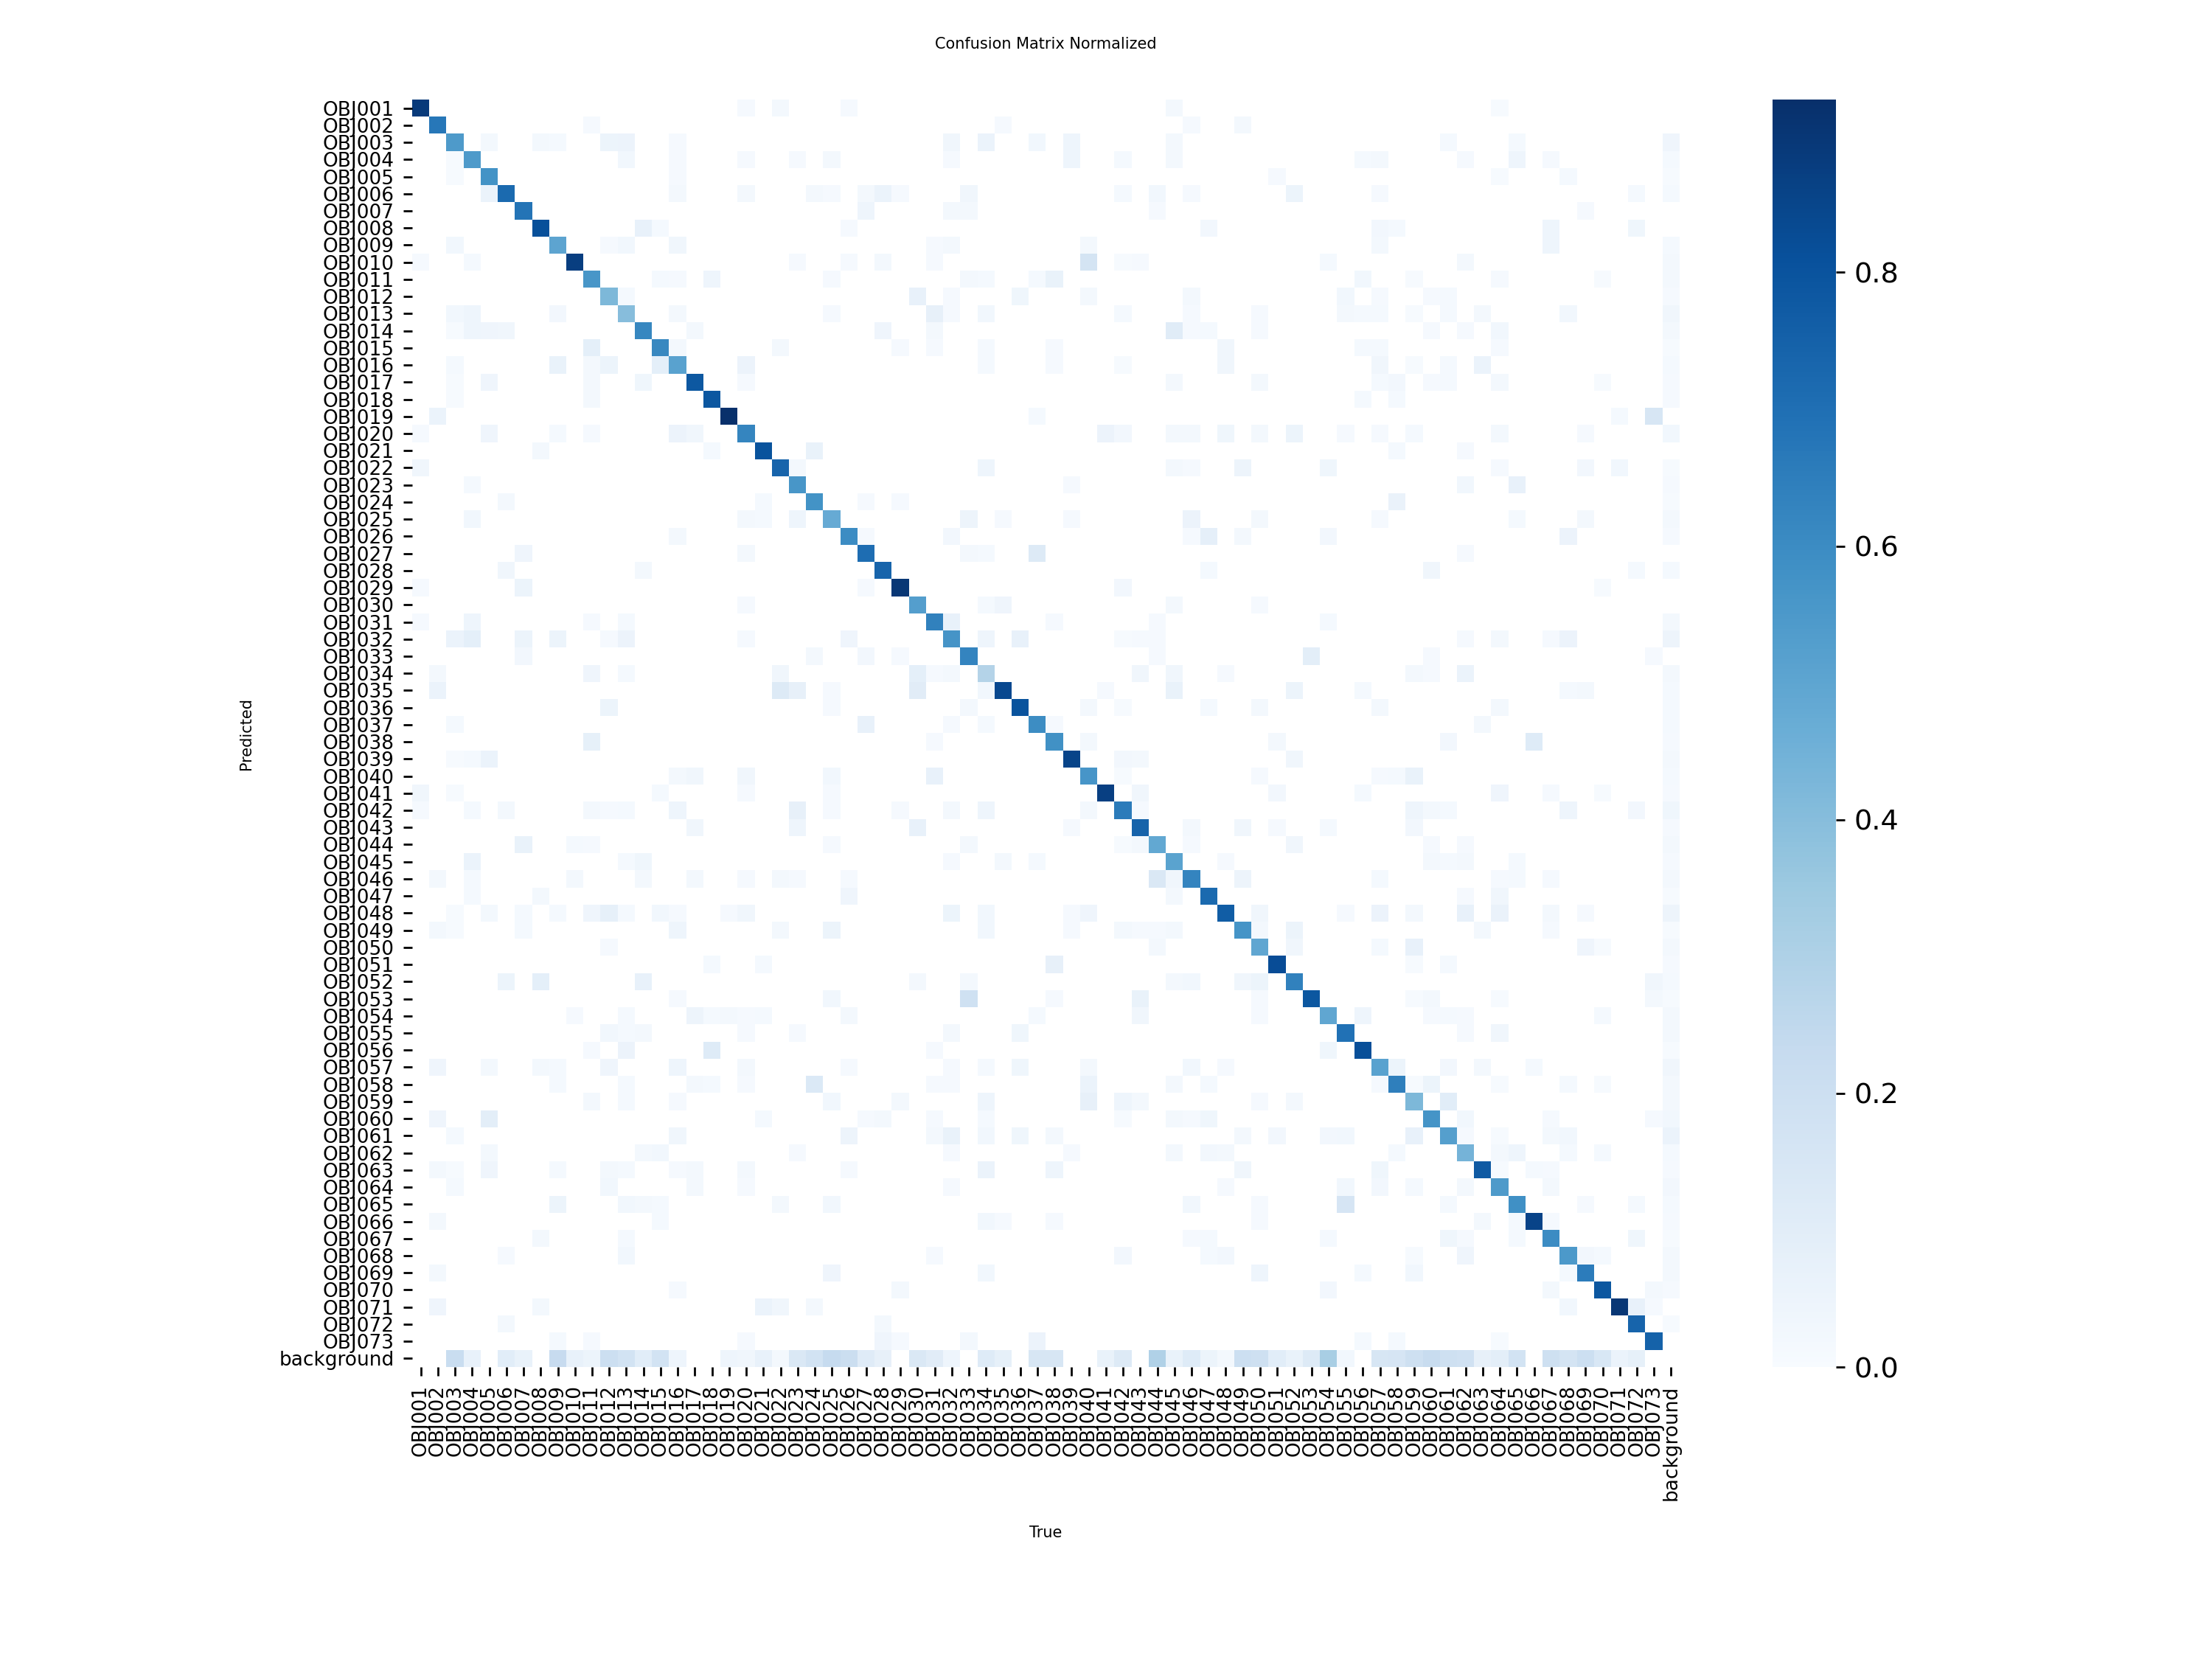

In [ ]:
display(IPImage(str(TEST_DIR / "confusion_matrix_normalized.png"), width=900))


0: 1024x1024 1 OBJ024, 1 OBJ027, 2 OBJ032s, 1 OBJ047, 3950.4ms
1: 1024x1024 1 OBJ019, 2 OBJ041s, 1 OBJ061, 3950.4ms
2: 1024x1024 1 OBJ004, 2 OBJ020s, 1 OBJ028, 1 OBJ038, 1 OBJ046, 3 OBJ048s, 1 OBJ063, 1 OBJ066, 2 OBJ070s, 3950.4ms
3: 1024x1024 1 OBJ026, 3 OBJ031s, 1 OBJ032, 2 OBJ065s, 3950.4ms
4: 1024x1024 2 OBJ014s, 1 OBJ036, 1 OBJ050, 3950.4ms
5: 1024x1024 1 OBJ044, 1 OBJ050, 2 OBJ064s, 3950.4ms
6: 1024x1024 1 OBJ023, 1 OBJ030, 1 OBJ043, 1 OBJ056, 3950.4ms
7: 1024x1024 2 OBJ013s, 1 OBJ016, 1 OBJ019, 3 OBJ020s, 1 OBJ022, 2 OBJ023s, 3 OBJ027s, 1 OBJ032, 1 OBJ043, 1 OBJ046, 5 OBJ048s, 1 OBJ053, 1 OBJ064, 2 OBJ067s, 3 OBJ069s, 2 OBJ072s, 3950.4ms
Speed: 66.8ms preprocess, 3950.4ms inference, 3.2ms postprocess per image at shape (1, 3, 1024, 1024)
Results saved to /content/drive/.shortcut-targets-by-id/1NXn7oX20Aw8ERXLlPt4_IGABaGaJsOWN/Objectdetection/runs/yolov8s_grid_test_predictions
grid_2x2_00025.jpg


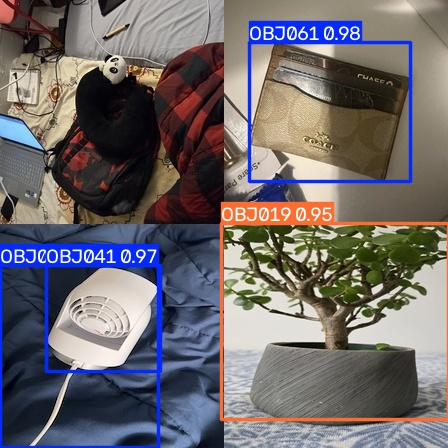

grid_2x2_00104.jpg


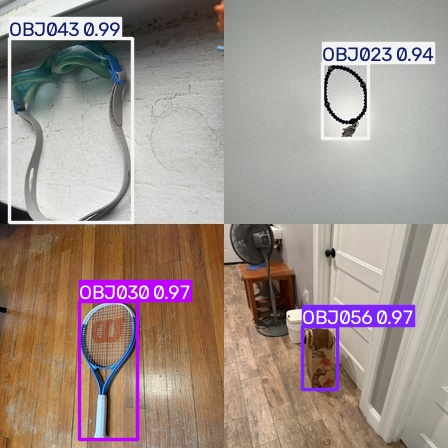

grid_2x2_00114.jpg


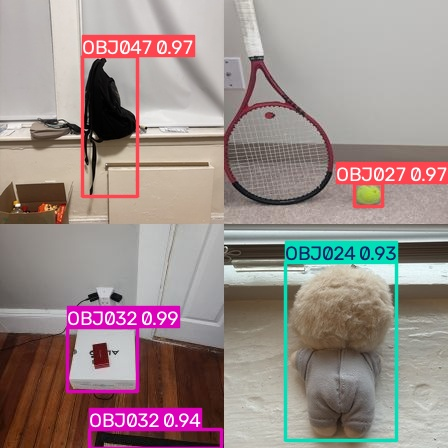

grid_2x2_00142.jpg


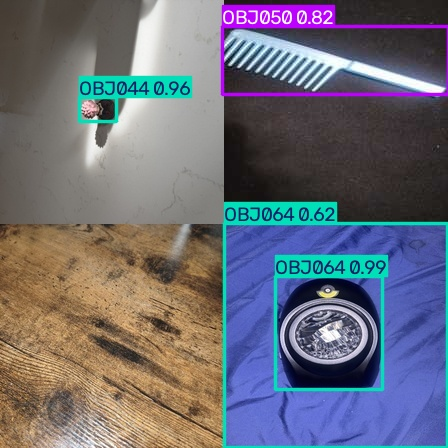

grid_2x2_00228.jpg


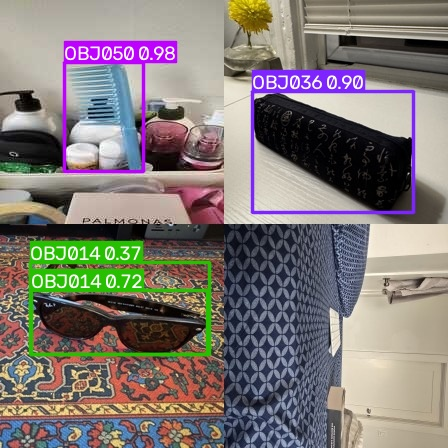

grid_2x2_00250.jpg


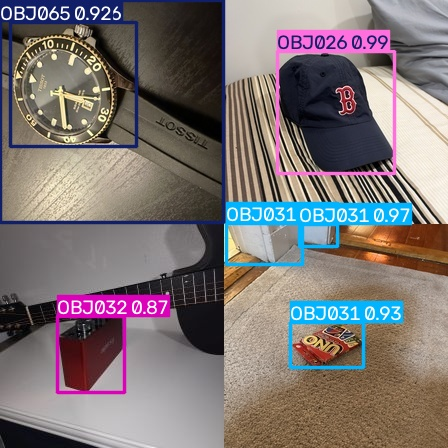

grid_3x3_00007.jpg


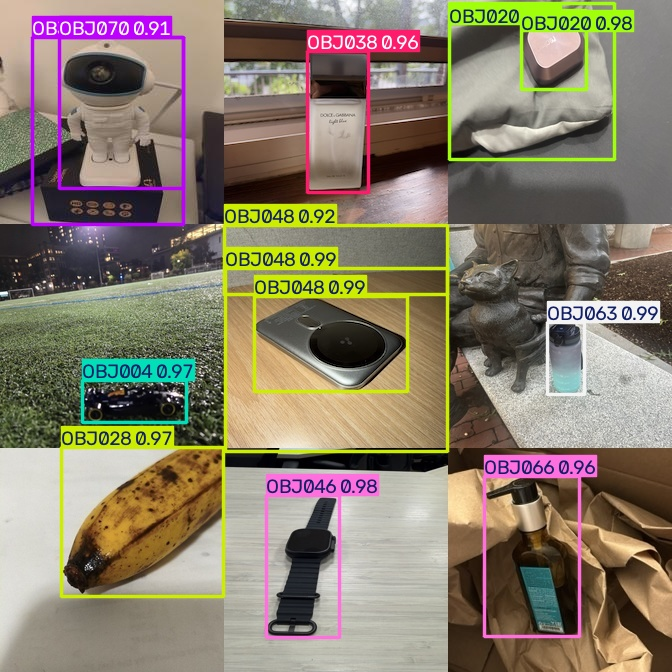

grid_5x5_00040.jpg


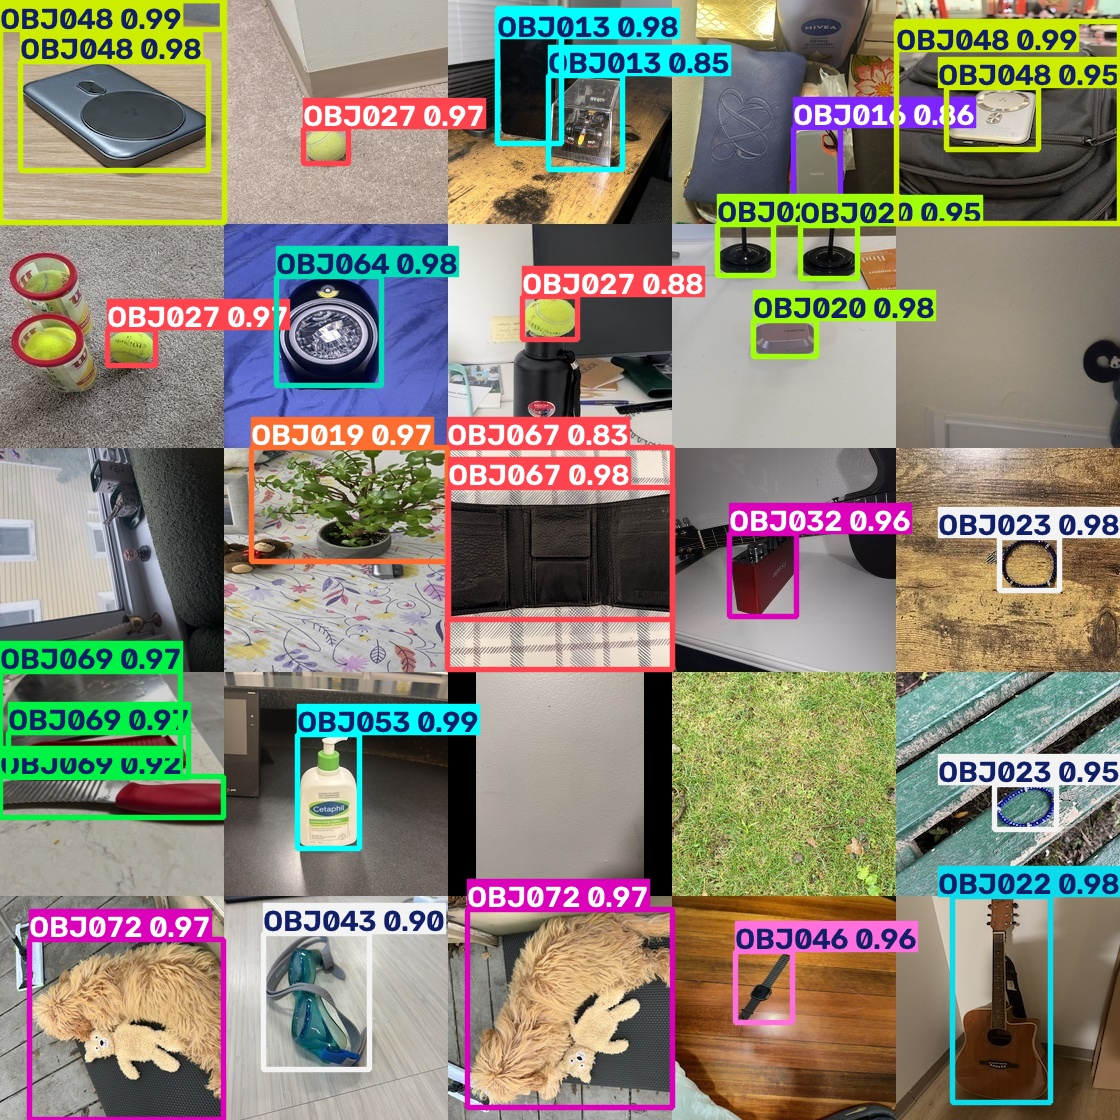

In [ ]:
test_images = sorted((GRID_DIR / "images" / "test").glob("*.jpg"))
samples = random.Random(42).sample(test_images, min(8, len(test_images)))

PRED_DIR = RUNS_DIR / f"{RUN_NAME}_test_predictions"

best_model.predict(
    source=[str(p) for p in samples],
    imgsz=1024,
    conf=0.25,
    save=True,
    project=str(RUNS_DIR),
    name=PRED_DIR.name,
    exist_ok=True,
)

for path in sorted(PRED_DIR.glob("*.jpg")):
    print(path.name)
    display(IPImage(str(path), width=700))